# PAN 2025 AI-Generated Text Detection: Exploratory Data Analysis

**Purpose:** This notebook provides a comprehensive analysis of the PAN 2025 dataset for AI-generated text detection. The goal is to understand the data characteristics, identify patterns that distinguish human from AI-generated text, and derive insights that can guide model development and experiment design.

**Key Questions:**
1. What are the fundamental characteristics of our training and validation data?
2. How do AI generators differ from human writing in measurable ways?
3. What features might help models generalize to out-of-distribution (OOD) data?
4. What pitfalls should we avoid when designing experiments?

---

## 1. Setup and Data Loading

In [1]:
import pandas as pd
import numpy as np
import json
import os
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from pathlib import Path
import re
import warnings
warnings.filterwarnings('ignore')

# Plot styling
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('husl')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

# Data paths - find project root and data directory
# Works regardless of where notebook is run from
def find_data_dir():
    # Try relative path first (from notebooks folder)
    candidates = [
        Path('../pan/src/pan-data'),
        Path('pan/src/pan-data'),
        Path('/Users/tanish/Desktop/CLEF2026/pan-2026/pan/src/pan-data'),
    ]
    for p in candidates:
        if p.exists():
            return p
    raise FileNotFoundError("Could not find pan-data directory")

DATA_DIR = find_data_dir()
TRAIN_PATH = DATA_DIR / 'train.jsonl'
VAL_PATH = DATA_DIR / 'val.jsonl'
EXTERNAL_DIR = DATA_DIR / 'external'

print(f"Data directory: {DATA_DIR.resolve()}")
print(f"External datasets: {[f.name for f in EXTERNAL_DIR.iterdir()]}")

Data directory: /Users/tanish/Desktop/CLEF2026/pan-2026/pan/src/pan-data
External datasets: ['ghostbuster.jsonl', 'raid.jsonl', 'turingbench.jsonl', 'm4.jsonl', 'hc3_wiki_processed.jsonl', 'hc3_wiki_raw.jsonl']


In [2]:
def load_jsonl(path):
    """Load a JSONL file into a DataFrame."""
    data = []
    with open(path, 'r', encoding='utf-8') as f:
        for line in f:
            if line.strip():
                data.append(json.loads(line))
    return pd.DataFrame(data)

# Load main datasets
train_df = load_jsonl(TRAIN_PATH)
val_df = load_jsonl(VAL_PATH)

print(f"Training samples: {len(train_df):,}")
print(f"Validation samples: {len(val_df):,}")
print(f"\nColumns: {train_df.columns.tolist()}")

Training samples: 23,707
Validation samples: 3,589

Columns: ['id', 'text', 'model', 'label', 'genre']


In [3]:
# Preview the data
train_df.head(3)

,id,text,model,label,genre
0,ea468d03-1973-5039-86b2-ff225bb92c4e,"Duke Ellington, a titan of jazz, revolutionize...",falcon3-10b-instruct,1,essays
1,0d05f269-6d67-521d-9b5d-cc18f482c6c1,I reflected on the shifting dynamics of media ...,o3-mini,1,essays
2,c2ec79f3-da80-58f8-bef0-3e0ea7ab072f,"In F. Scott Fitzgerald's ""The Great Gatsby,"" t...",gpt-4o,1,essays


### Data Schema Understanding

| Field | Description | Importance for Modeling |
|-------|-------------|------------------------|
| `id` | Unique identifier | Used for submission/tracking |
| `text` | The document content | **Primary input feature** |
| `model` | Source generator (e.g., 'human', 'gpt-4o', 'deepseek-r1') | Useful for stratification, but **not available at test time** |
| `label` | 0 = human, 1 = AI-generated | **Target variable** |
| `genre` | Text category (e.g., 'essays') | May help understand domain shifts |

**⚠️ Critical Note:** The `model` field tells us which AI generated the text, but this information is **not available during inference**. Models that inadvertently learn to recognize specific generators (rather than general AI patterns) will fail on OOD data with unseen generators.

---
## 2. Label Distribution Analysis

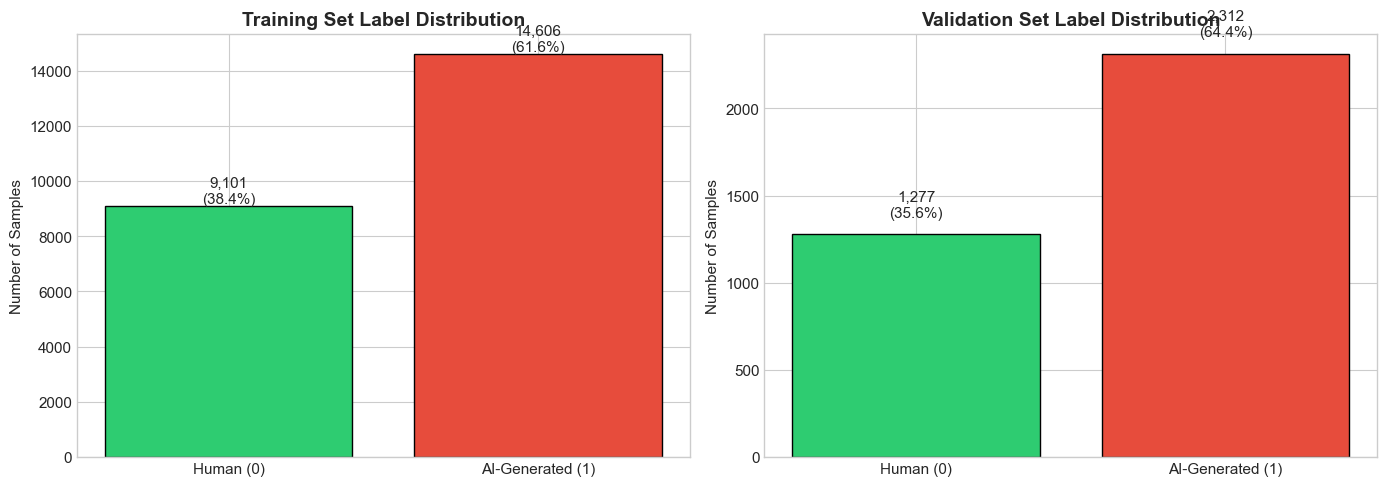

Label Distribution Summary:
  Training: {1: 14606, 0: 9101}
  Validation: {1: 2312, 0: 1277}


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, (name, df) in zip(axes, [('Training', train_df), ('Validation', val_df)]):
    counts = df['label'].value_counts().sort_index()
    colors = ['#2ecc71', '#e74c3c']  # Green for human, red for AI
    bars = ax.bar(['Human (0)', 'AI-Generated (1)'], counts.values, color=colors, edgecolor='black')
    ax.set_title(f'{name} Set Label Distribution', fontsize=14, fontweight='bold')
    ax.set_ylabel('Number of Samples')
    
    # Add percentage labels
    total = counts.sum()
    for bar, count in zip(bars, counts.values):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 100, 
                f'{count:,}\n({count/total*100:.1f}%)', ha='center', fontsize=11)

plt.tight_layout()
plt.show()

# Print exact numbers
print("Label Distribution Summary:")
print(f"  Training: {train_df['label'].value_counts().to_dict()}")
print(f"  Validation: {val_df['label'].value_counts().to_dict()}")

### 📊 Insight: Label Balance

**What this means:**
- The dataset appears to have a specific human:AI ratio. Understanding this ratio is crucial for:
  1. **Choosing appropriate metrics** (ROC-AUC is robust to imbalance; F1 is not)
  2. **Setting classification thresholds** (0.5 may not be optimal if classes are imbalanced)
  3. **Sampling strategies** (whether to use oversampling/undersampling)

**Implications for experiments:**
- If highly imbalanced: Consider stratified sampling for cross-validation
- If balanced: Standard approaches should work well
- The test set distribution is unknown - models should be calibrated for various ratios

---
## 3. Text Length Analysis

Text length is a fundamental characteristic that can:
1. Reveal biases in the dataset (do AI texts tend to be longer/shorter?)
2. Inform model architecture choices (max sequence length, chunking strategies)
3. Highlight potential shortcuts models might exploit

In [5]:
# Calculate text lengths
train_df['char_length'] = train_df['text'].str.len()
train_df['word_count'] = train_df['text'].str.split().str.len()
train_df['sentence_count'] = train_df['text'].str.count(r'[.!?]+')

val_df['char_length'] = val_df['text'].str.len()
val_df['word_count'] = val_df['text'].str.split().str.len()
val_df['sentence_count'] = val_df['text'].str.count(r'[.!?]+')

# Summary statistics by label
print("=" * 60)
print("TEXT LENGTH STATISTICS (Training Set)")
print("=" * 60)
for label, name in [(0, 'Human'), (1, 'AI-Generated')]:
    subset = train_df[train_df['label'] == label]
    print(f"\n{name} Texts:")
    print(f"  Word count:  mean={subset['word_count'].mean():.0f}, median={subset['word_count'].median():.0f}, "
          f"min={subset['word_count'].min()}, max={subset['word_count'].max()}")
    print(f"  Char length: mean={subset['char_length'].mean():.0f}, median={subset['char_length'].median():.0f}")

TEXT LENGTH STATISTICS (Training Set)

Human Texts:
  Word count:  mean=695, median=670, min=150, max=4892
  Char length: mean=3942, median=3712

AI-Generated Texts:
  Word count:  mean=575, median=546, min=33, max=2018
  Char length: mean=3580, median=3473


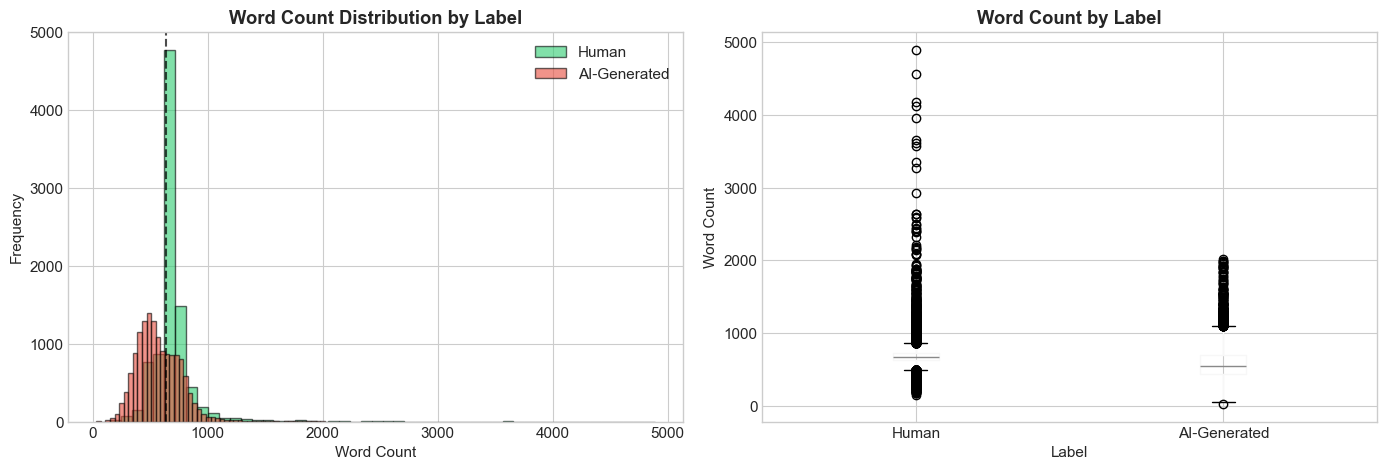

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Word count distribution
for label, color, name in [(0, '#2ecc71', 'Human'), (1, '#e74c3c', 'AI-Generated')]:
    subset = train_df[train_df['label'] == label]
    axes[0].hist(subset['word_count'], bins=50, alpha=0.6, label=name, color=color, edgecolor='black')
axes[0].set_xlabel('Word Count')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Word Count Distribution by Label', fontweight='bold')
axes[0].legend()
axes[0].axvline(train_df['word_count'].median(), color='black', linestyle='--', alpha=0.7, label='Overall Median')

# Box plot comparison
train_df.boxplot(column='word_count', by='label', ax=axes[1])
axes[1].set_xticklabels(['Human', 'AI-Generated'])
axes[1].set_xlabel('Label')
axes[1].set_ylabel('Word Count')
axes[1].set_title('Word Count by Label', fontweight='bold')
plt.suptitle('')  # Remove automatic title

plt.tight_layout()
plt.show()

### 📊 Insight: Text Length Patterns

**What to look for:**
- **If AI texts are consistently longer/shorter:** This could be a spurious correlation that models exploit. A model might learn "long text = AI" rather than actual linguistic patterns.
- **If distributions overlap significantly:** Length alone won't be a useful discriminator, which is good for generalization.

**Implications for experiments:**
1. **Chunking strategy:** If texts exceed typical transformer limits (512-4096 tokens), implement sliding window or hierarchical approaches
2. **Length normalization:** Consider whether to control for length in feature engineering
3. **Robustness testing:** Evaluate models on length-matched subsets to ensure they're not exploiting length shortcuts

---
## 4. Model (Generator) Analysis

Understanding which AI models generated the training data is crucial for:
1. Ensuring diverse representation of AI writing styles
2. Identifying potential gaps (missing generator families)
3. Understanding what "AI-generated" means in this context

In [7]:
# Model distribution
model_counts = train_df['model'].value_counts()
print(f"Unique generators in training data: {len(model_counts)}")
print("\nGenerator Distribution:")
print(model_counts.to_string())

Unique generators in training data: 23

Generator Distribution:
model
human                           9101
gpt-3.5-turbo                   1374
gpt-4o-mini                     1358
gpt-4o                          1336
ministral-8b-instruct-2410      1100
gemini-2.0-flash                1079
o3-mini                         1075
gemini-1.5-pro                  1072
llama-3.1-8b-instruct           1063
deepseek-r1-distill-qwen-32b     901
falcon3-10b-instruct             879
llama-3.3-70b-instruct           405
gpt-4.5-preview                  278
gpt-4-turbo-paraphrase           276
gemini-pro                       276
gpt-4-turbo                      272
qwen1.5-72b-chat-8bit            271
llama-2-70b-chat                 269
mistral-7b-instruct-v0.2         266
gemini-pro-paraphrase            265
text-bison-002                   265
mixtral-8x7b-instruct-v0.1       264
llama-2-7b-chat                  262


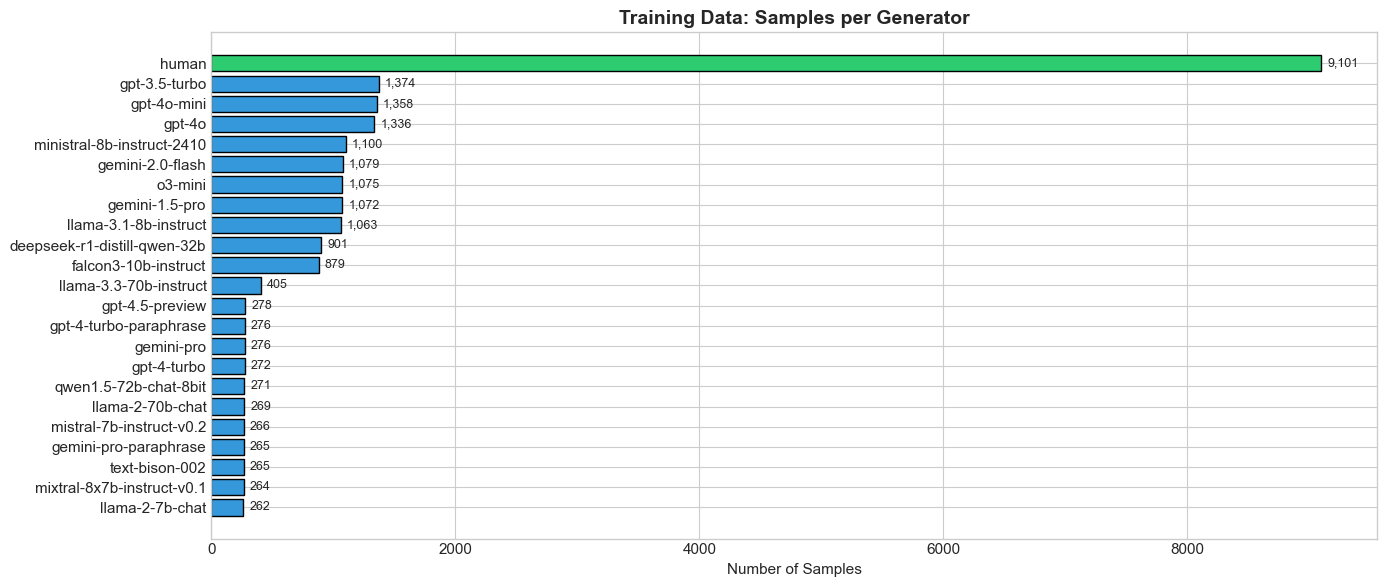

In [8]:
# Visualize model distribution
fig, ax = plt.subplots(figsize=(14, 6))

colors = ['#2ecc71' if m == 'human' else '#3498db' for m in model_counts.index]
bars = ax.barh(model_counts.index, model_counts.values, color=colors, edgecolor='black')
ax.set_xlabel('Number of Samples')
ax.set_title('Training Data: Samples per Generator', fontsize=14, fontweight='bold')
ax.invert_yaxis()

# Add count labels
for bar, count in zip(bars, model_counts.values):
    ax.text(bar.get_width() + 50, bar.get_y() + bar.get_height()/2, 
            f'{count:,}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

In [9]:
# Categorize generators by family
def categorize_model(model_name):
    model_lower = model_name.lower()
    if model_lower == 'human':
        return 'Human'
    elif 'gpt' in model_lower or 'openai' in model_lower:
        return 'OpenAI (GPT)'
    elif 'claude' in model_lower:
        return 'Anthropic (Claude)'
    elif 'gemini' in model_lower or 'google' in model_lower:
        return 'Google (Gemini)'
    elif 'llama' in model_lower or 'meta' in model_lower:
        return 'Meta (Llama)'
    elif 'deepseek' in model_lower:
        return 'DeepSeek'
    elif 'mistral' in model_lower:
        return 'Mistral'
    elif 'qwen' in model_lower:
        return 'Alibaba (Qwen)'
    else:
        return 'Other'

train_df['model_family'] = train_df['model'].apply(categorize_model)

family_counts = train_df['model_family'].value_counts()
print("Generator Family Distribution:")
print(family_counts.to_string())

Generator Family Distribution:
model_family
Human              9101
OpenAI (GPT)       4894
Other              3583
Google (Gemini)    2692
Meta (Llama)       1999
DeepSeek            901
Alibaba (Qwen)      271
Mistral             266


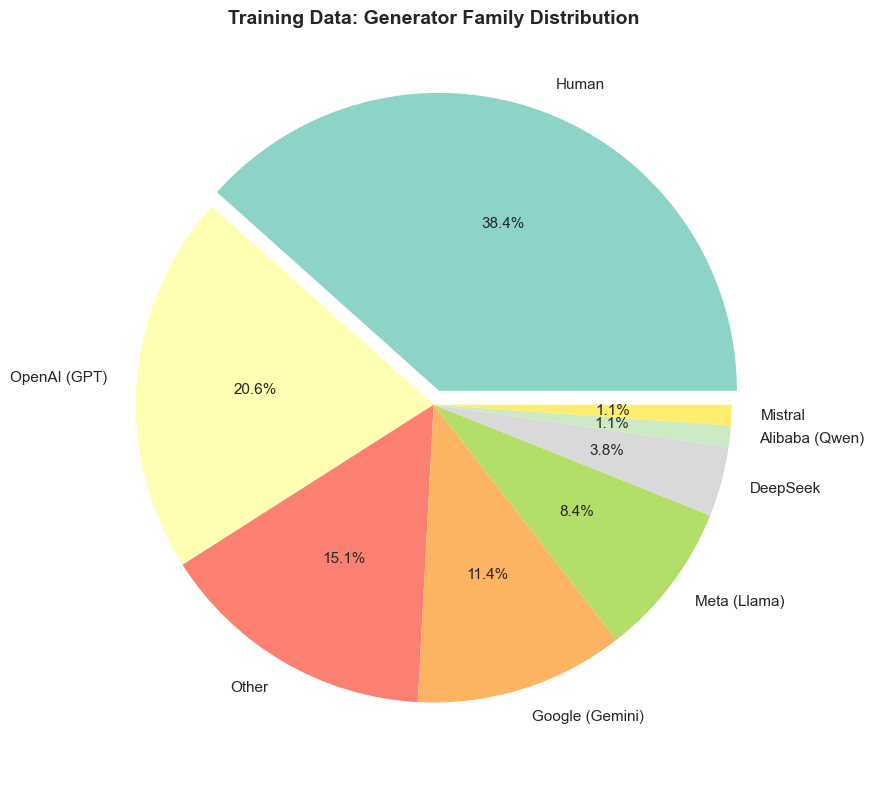

In [10]:
# Pie chart of model families
fig, ax = plt.subplots(figsize=(10, 8))

colors = plt.cm.Set3(np.linspace(0, 1, len(family_counts)))
wedges, texts, autotexts = ax.pie(family_counts.values, labels=family_counts.index, 
                                   autopct='%1.1f%%', colors=colors, 
                                   explode=[0.05 if f == 'Human' else 0 for f in family_counts.index])
ax.set_title('Training Data: Generator Family Distribution', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

### 📊 Insight: Generator Diversity

**What this means:**
- The dataset includes texts from multiple AI model families
- Each family has distinct characteristics (e.g., GPT tends toward verbose explanations, Claude uses more structured formatting)

**Critical consideration for OOD generalization:**
- Models trained on GPT-4 + Claude might fail on Mistral or open-source models
- New models (e.g., future GPT-5) will have different signatures
- **The goal is to learn general "AI-ness," not specific model fingerprints**

**Implications for experiments:**
1. **Cross-generator validation:** Hold out entire model families during training to test generalization
2. **Avoid model-specific features:** Features like "uses Claude's formatting style" won't generalize
3. **Focus on fundamental differences:** Burstiness, perplexity patterns, vocabulary diversity

---
## 5. Genre Analysis

Understanding genre distribution helps us:
1. Know what types of text we're classifying
2. Identify potential domain shift issues
3. Design experiments that test across genres

In [11]:
print("Genre Distribution (Training):")
genre_counts = train_df['genre'].value_counts()
print(genre_counts.to_string())

print(f"\nUnique genres: {train_df['genre'].nunique()}")

Genre Distribution (Training):
genre
fiction    14697
essays      4661
news        4349

Unique genres: 3


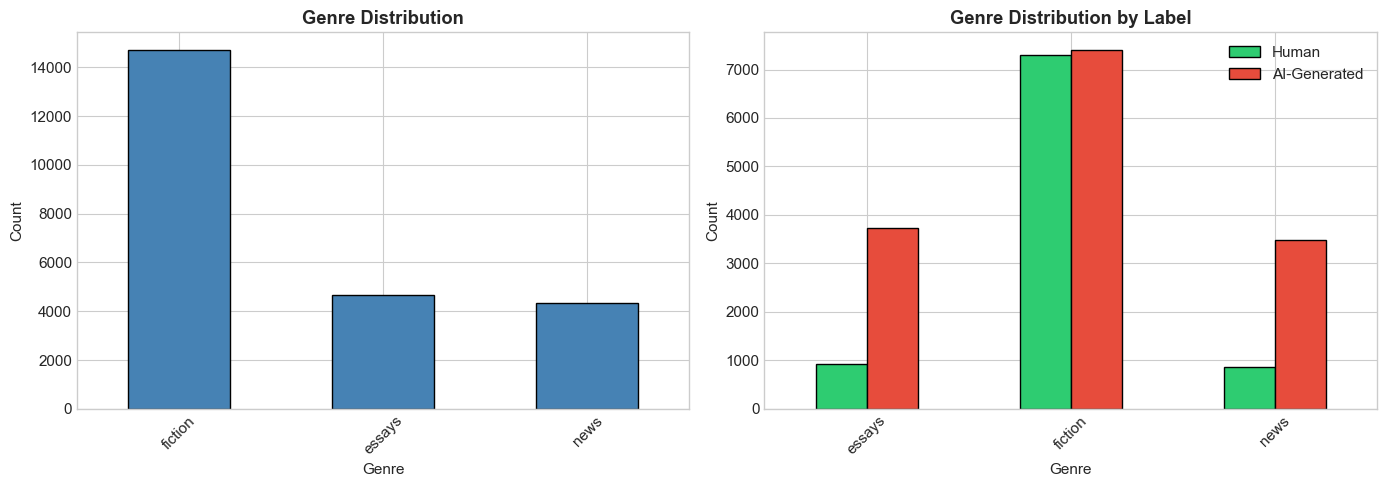

In [12]:
# Genre distribution visualization
if train_df['genre'].nunique() > 1:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Overall genre distribution
    genre_counts.plot(kind='bar', ax=axes[0], color='steelblue', edgecolor='black')
    axes[0].set_title('Genre Distribution', fontweight='bold')
    axes[0].set_xlabel('Genre')
    axes[0].set_ylabel('Count')
    axes[0].tick_params(axis='x', rotation=45)
    
    # Genre × Label distribution
    genre_label = train_df.groupby(['genre', 'label']).size().unstack(fill_value=0)
    genre_label.plot(kind='bar', ax=axes[1], color=['#2ecc71', '#e74c3c'], edgecolor='black')
    axes[1].set_title('Genre Distribution by Label', fontweight='bold')
    axes[1].set_xlabel('Genre')
    axes[1].set_ylabel('Count')
    axes[1].legend(['Human', 'AI-Generated'])
    axes[1].tick_params(axis='x', rotation=45)
    
    plt.tight_layout()
    plt.show()
else:
    print(f"Dataset contains only one genre: {train_df['genre'].iloc[0]}")

### 📊 Insight: Genre Coverage

**Implications for experiments:**
1. **Genre-specific patterns:** Essays, news articles, and creative writing have different legitimate styles
2. **Cross-genre evaluation:** If training on essays, test on other genres to check generalization
3. **Prompt engineering:** AI text varies based on the prompt/task - a "write an essay" prompt produces different text than "write a poem"

---
## 6. Linguistic Feature Analysis

These features capture writing style characteristics that may differ between human and AI text.

In [13]:
def compute_linguistic_features(text):
    """Compute various linguistic features for a text."""
    words = text.split()
    sentences = re.split(r'[.!?]+', text)
    sentences = [s.strip() for s in sentences if s.strip()]
    
    # Basic counts
    word_count = len(words)
    sentence_count = len(sentences) if sentences else 1
    
    # Average word length
    avg_word_length = np.mean([len(w) for w in words]) if words else 0
    
    # Average sentence length
    avg_sentence_length = word_count / sentence_count
    
    # Vocabulary richness (type-token ratio)
    unique_words = set(w.lower() for w in words)
    ttr = len(unique_words) / word_count if word_count > 0 else 0
    
    # Punctuation density
    punct_count = sum(1 for c in text if c in '.,!?;:"\'()-')
    punct_density = punct_count / len(text) if text else 0
    
    # Question/exclamation ratio
    question_count = text.count('?')
    exclamation_count = text.count('!')
    
    # Paragraph count (approximated by double newlines)
    para_count = len(re.split(r'\n\n+', text))
    
    return {
        'avg_word_length': avg_word_length,
        'avg_sentence_length': avg_sentence_length,
        'type_token_ratio': ttr,
        'punct_density': punct_density,
        'question_count': question_count,
        'exclamation_count': exclamation_count,
        'para_count': para_count
    }

# Compute features for a sample (full computation is slow)
print("Computing linguistic features (sampling 5000 texts for speed)...")
sample_df = train_df.sample(min(5000, len(train_df)), random_state=42).copy()

features_list = sample_df['text'].apply(compute_linguistic_features)
features_df = pd.DataFrame(features_list.tolist())
sample_df = pd.concat([sample_df.reset_index(drop=True), features_df], axis=1)

print("Done!")

Computing linguistic features (sampling 5000 texts for speed)...
Done!


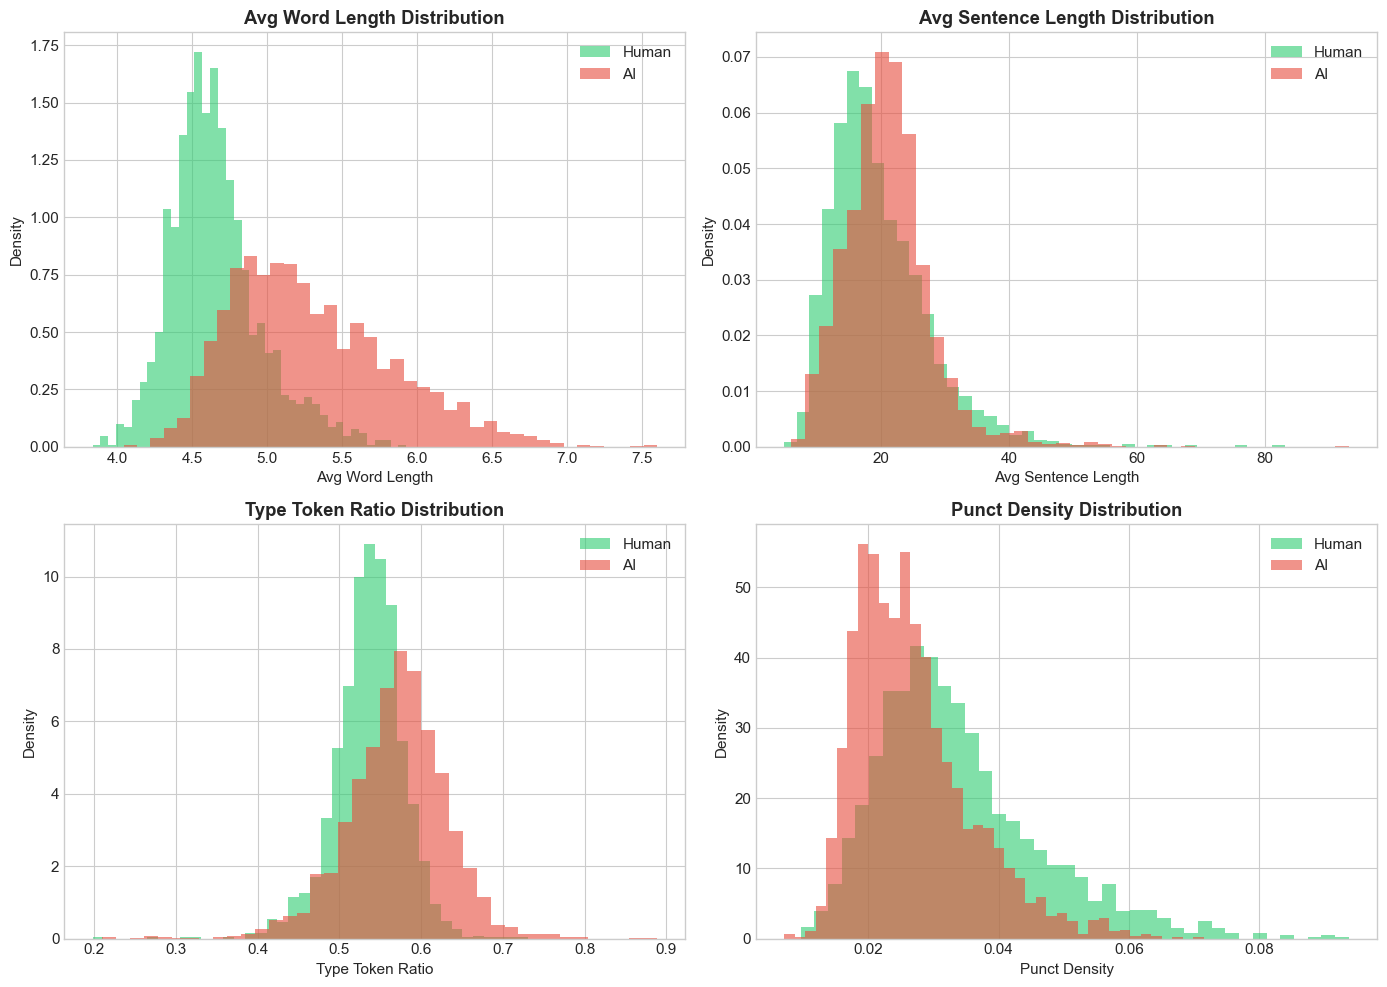

In [14]:
# Compare features by label
feature_cols = ['avg_word_length', 'avg_sentence_length', 'type_token_ratio', 'punct_density']

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, col in zip(axes, feature_cols):
    for label, color, name in [(0, '#2ecc71', 'Human'), (1, '#e74c3c', 'AI')]:
        subset = sample_df[sample_df['label'] == label][col]
        ax.hist(subset, bins=40, alpha=0.6, label=name, color=color, density=True)
    ax.set_xlabel(col.replace('_', ' ').title())
    ax.set_ylabel('Density')
    ax.set_title(f'{col.replace("_", " ").title()} Distribution', fontweight='bold')
    ax.legend()

plt.tight_layout()
plt.show()

In [15]:
# Statistical comparison
print("=" * 70)
print("LINGUISTIC FEATURE COMPARISON (Human vs AI)")
print("=" * 70)

for col in feature_cols:
    human_mean = sample_df[sample_df['label'] == 0][col].mean()
    ai_mean = sample_df[sample_df['label'] == 1][col].mean()
    diff_pct = ((ai_mean - human_mean) / human_mean) * 100 if human_mean != 0 else 0
    
    print(f"\n{col.replace('_', ' ').title()}:")
    print(f"  Human: {human_mean:.4f}")
    print(f"  AI:    {ai_mean:.4f}")
    print(f"  Diff:  {diff_pct:+.1f}%")

LINGUISTIC FEATURE COMPARISON (Human vs AI)

Avg Word Length:
  Human: 4.6510
  AI:    5.2949
  Diff:  +13.8%

Avg Sentence Length:
  Human: 19.8816
  AI:    21.1111
  Diff:  +6.2%

Type Token Ratio:
  Human: 0.5360
  AI:    0.5704
  Diff:  +6.4%

Punct Density:
  Human: 0.0339
  AI:    0.0269
  Diff:  -20.6%


### 📊 Insight: Linguistic Patterns

**Key findings to look for:**

1. **Type-Token Ratio (Vocabulary Diversity):**
   - If AI has lower TTR: AI may be more repetitive, using a narrower vocabulary
   - This is a known characteristic of many language models

2. **Sentence Length:**
   - AI models often produce more uniform sentence lengths
   - Humans have higher variance ("burstiness")

3. **Punctuation Patterns:**
   - AI may overuse certain punctuation (e.g., colons, em-dashes)
   - Human text often has more varied punctuation usage

**Implications for experiments:**
1. **Stylometric features can help** but may also overfit to specific generators
2. **These patterns may not hold for all AI models** - test generalization carefully
3. **Consider robustness:** Can adversaries easily modify punctuation/sentence length to evade detection?

---
## 7. Cross-Feature Analysis

In [16]:
# Text length by model
model_length_stats = train_df.groupby('model')['word_count'].agg(['mean', 'median', 'std']).round(1)
model_length_stats = model_length_stats.sort_values('mean', ascending=False)
print("Average Word Count by Model:")
print(model_length_stats.to_string())

Average Word Count by Model:
                               mean  median    std
model                                             
deepseek-r1-distill-qwen-32b  849.8   818.0  336.0
llama-3.3-70b-instruct        745.6   782.0  174.6
human                         695.5   670.0  209.8
o3-mini                       679.1   686.0  196.3
gpt-4o-mini                   621.5   659.0  156.6
ministral-8b-instruct-2410    620.2   652.0  180.6
gpt-4.5-preview               603.0   569.5  170.3
gemini-2.0-flash              595.1   603.0  110.1
gpt-4o                        590.5   590.0  152.7
llama-3.1-8b-instruct         572.6   554.0  160.3
falcon3-10b-instruct          565.9   561.0  145.5
mixtral-8x7b-instruct-v0.1    530.6   518.0  131.1
mistral-7b-instruct-v0.2      530.3   501.5  130.5
text-bison-002                518.7   501.0  120.3
gpt-4-turbo                   517.2   497.0  129.0
gemini-1.5-pro                506.3   504.0  132.4
llama-2-70b-chat              501.2   492.0  107.1
ge

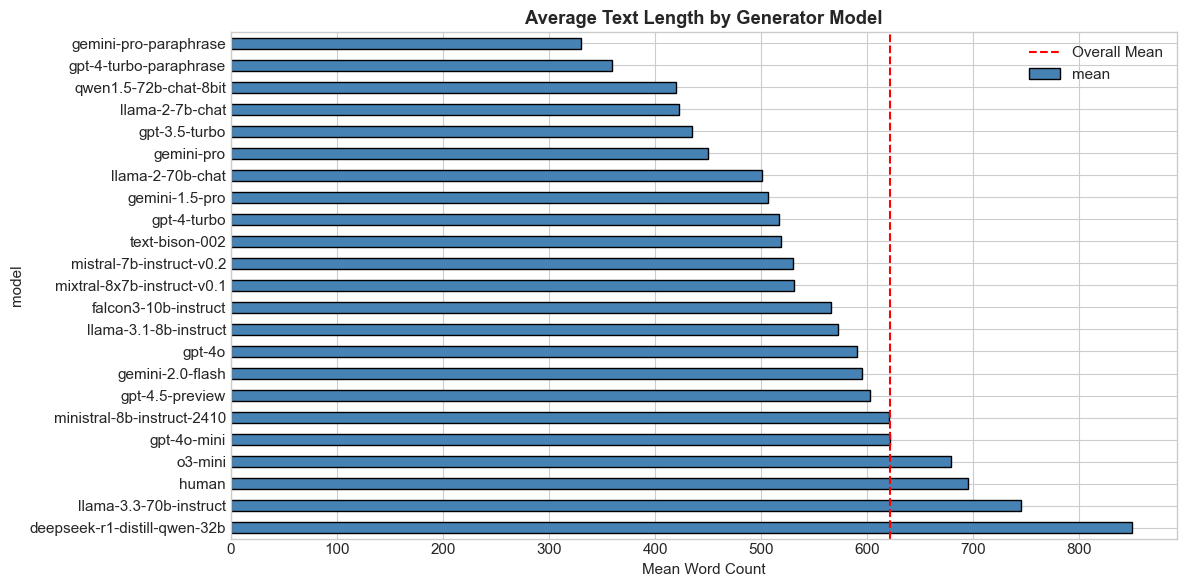

In [17]:
# Heatmap of word count by model
fig, ax = plt.subplots(figsize=(12, 6))

model_length_stats['mean'].plot(kind='barh', ax=ax, color='steelblue', edgecolor='black')
ax.axvline(train_df['word_count'].mean(), color='red', linestyle='--', label='Overall Mean')
ax.set_xlabel('Mean Word Count')
ax.set_title('Average Text Length by Generator Model', fontweight='bold')
ax.legend()

plt.tight_layout()
plt.show()

### 📊 Insight: Model-Specific Patterns

**Warning signs to watch for:**
- If certain models consistently produce longer/shorter texts, a model might learn "long text from model X = AI"
- This is a **spurious correlation** that won't generalize

**Implications for experiments:**
1. **Length normalization:** Consider controlling for length in experiments
2. **Stratified evaluation:** Report performance separately for different text lengths
3. **Adversarial testing:** Can detection be evaded by adjusting text length?

---
## 8. External (OOD) Datasets Analysis

Understanding the external datasets is crucial because **OOD generalization is the main challenge** in this task.

In [18]:
# Load and analyze external datasets
external_files = [f.name for f in EXTERNAL_DIR.iterdir() if f.suffix == '.jsonl']
print(f"External datasets found: {external_files}")

external_dfs = {}
for fname in external_files:
    path = EXTERNAL_DIR / fname
    df = load_jsonl(path)
    name = fname.replace('.jsonl', '')
    external_dfs[name] = df
    print(f"\n{name}: {len(df):,} samples")
    print(f"  Columns: {df.columns.tolist()}")
    if 'label' in df.columns:
        print(f"  Labels: {df['label'].value_counts().to_dict()}")

External datasets found: ['ghostbuster.jsonl', 'raid.jsonl', 'turingbench.jsonl', 'm4.jsonl', 'hc3_wiki_processed.jsonl', 'hc3_wiki_raw.jsonl']

ghostbuster: 500 samples
  Columns: ['text', 'label', 'source']
  Labels: {1: 257, 0: 243}

raid: 500 samples
  Columns: ['text', 'label', 'source']
  Labels: {0: 253, 1: 247}

turingbench: 500 samples
  Columns: ['text', 'label', 'source']
  Labels: {0: 253, 1: 247}

m4: 500 samples
  Columns: ['text', 'label', 'source']
  Labels: {0: 255, 1: 245}

hc3_wiki_processed: 1,684 samples
  Columns: ['text', 'label', 'source']
  Labels: {1: 842, 0: 842}

hc3_wiki_raw: 842 samples
  Columns: ['question', 'human_answers', 'chatgpt_answers']


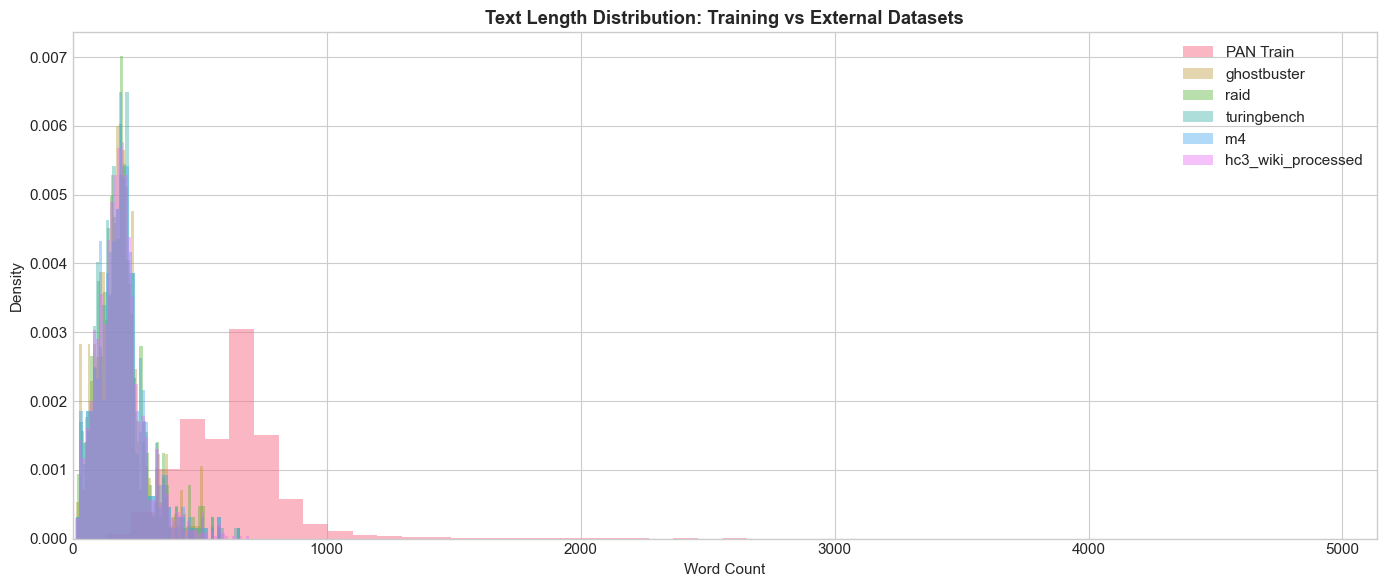

In [19]:
# Compare text length distributions across datasets
fig, ax = plt.subplots(figsize=(14, 6))

# Add training data
train_df['word_count'].hist(ax=ax, bins=50, alpha=0.5, label='PAN Train', density=True)

# Add external datasets
for name, df in external_dfs.items():
    if 'text' in df.columns:
        word_counts = df['text'].str.split().str.len()
        word_counts.hist(ax=ax, bins=50, alpha=0.4, label=name, density=True)

ax.set_xlabel('Word Count')
ax.set_ylabel('Density')
ax.set_title('Text Length Distribution: Training vs External Datasets', fontweight='bold')
ax.legend()
ax.set_xlim(0, ax.get_xlim()[1])  # Start from 0

plt.tight_layout()
plt.show()

In [20]:
# Analyze source/model distribution in external datasets
print("=" * 60)
print("EXTERNAL DATASET SOURCES/MODELS")
print("=" * 60)

for name, df in external_dfs.items():
    print(f"\n{name.upper()}:")
    if 'source' in df.columns:
        print(f"  Sources: {df['source'].value_counts().to_dict()}")
    if 'model' in df.columns:
        print(f"  Models: {df['model'].value_counts().head(5).to_dict()}")
    
    # Sample text preview
    if 'text' in df.columns:
        sample_text = df['text'].iloc[0][:200]
        print(f"  Sample: {sample_text}...")

EXTERNAL DATASET SOURCES/MODELS

GHOSTBUSTER:
  Sources: {'ghostbuster': 500}
  Sample: Linear network coding is a method of transmitting data across a network in which the intermediate nodes in the network are permitted to perform coding operations on the data they receive, rather than ...

RAID:
  Sources: {'raid': 500}
  Sample: An array is a data structure that stores a collection of items, typically in a contiguous block of memory. The items in an array are usually of the same data type, and are accessed using an index.



...

TURINGBENCH:
  Sources: {'turingbench': 500}
  Sample: An epigenetic clock is a biochemical test that can be used to measure age. The test is based on DNA methylation levels, measuring the accumulation of methyl groups to one's DNA molecules....

M4:
  Sources: {'m4': 500}
  Sample: Computational statistics is a field of study that combines statistical methods with computational techniques to analyze and solve problems in statistical data analysis. It invol

### 📊 Insight: OOD Challenge

**Why external datasets matter:**
- These represent text from **different domains, generators, and time periods**
- Performance on external data is the true test of generalization
- The README shows previous models achieved ~55-59% ROC-AUC on HC3 (barely above random!)

**Key differences to observe:**
1. **Different AI models:** External datasets may use older or different generators
2. **Different domains:** Scientific, wiki, QA formats differ from essays
3. **Different lengths:** Some datasets may have much shorter/longer texts
4. **Different topics:** Content areas the model hasn't seen

**Implications for experiments:**
1. **Always evaluate on external data** - high validation accuracy means nothing if OOD fails
2. **Analyze failure cases** - understanding WHY models fail on OOD data guides improvements
3. **Consider domain adaptation** - techniques to make models more robust
4. **Ensemble approaches** - combining models trained on different data distributions

---
## 9. Key Insights Summary

### Dataset Characteristics

| Aspect | Finding | Implication |
|--------|---------|-------------|
| **Size** | ~24K train, ~3.5K val | Sufficient for fine-tuning transformers |
| **Balance** | Check pie chart above | May need stratified sampling if imbalanced |
| **Generators** | Multiple AI families represented | Good for diversity, but OOD generators will differ |
| **Genres** | Primarily essays | May not generalize to other text types |
| **Text Length** | Variable, some very long | Need chunking strategy for transformers |

### Critical Challenges

1. **OOD Generalization is the bottleneck**
   - Models easily achieve >99% on validation
   - But drop to ~55% on external data (near random)
   - This suggests models are learning dataset-specific patterns, not general AI signatures

2. **Spurious Correlations Risk**
   - Text length, specific punctuation patterns, model-specific vocabulary
   - These "shortcuts" work in-distribution but fail OOD

3. **Evolving AI Landscape**
   - New models constantly released
   - Detection methods must be forward-compatible

### Recommendations for Future Experiments

1. **Evaluation Strategy**
   - Always report OOD performance alongside validation scores
   - Use cross-generator validation (hold out model families)
   - Test on multiple external datasets

2. **Feature Engineering**
   - Focus on fundamental linguistic patterns (burstiness, perplexity)
   - Avoid features tied to specific generators
   - Consider length-normalized features

3. **Model Architecture**
   - Transformers (DeBERTa) show modest OOD improvement over baselines
   - Consider perplexity-based approaches using language models
   - Explore contrastive learning for domain invariance

4. **Data Augmentation**
   - Generate adversarial examples (paraphrased AI text)
   - Include more diverse AI generators in training
   - Consider domain randomization techniques

In [21]:
# Final summary statistics
print("=" * 70)
print("FINAL SUMMARY: PAN 2025 DATASET")
print("=" * 70)
print(f"\nTraining Set:")
print(f"  Total samples: {len(train_df):,}")
print(f"  Human samples: {(train_df['label'] == 0).sum():,} ({(train_df['label'] == 0).mean()*100:.1f}%)")
print(f"  AI samples: {(train_df['label'] == 1).sum():,} ({(train_df['label'] == 1).mean()*100:.1f}%)")
print(f"  Unique generators: {train_df['model'].nunique()}")
print(f"  Unique genres: {train_df['genre'].nunique()}")
print(f"  Avg word count: {train_df['word_count'].mean():.0f}")

print(f"\nValidation Set:")
print(f"  Total samples: {len(val_df):,}")

print(f"\nExternal Datasets:")
for name, df in external_dfs.items():
    print(f"  {name}: {len(df):,} samples")

print("\n" + "=" * 70)
print("END OF EXPLORATORY DATA ANALYSIS")
print("=" * 70)

FINAL SUMMARY: PAN 2025 DATASET

Training Set:
  Total samples: 23,707
  Human samples: 9,101 (38.4%)
  AI samples: 14,606 (61.6%)
  Unique generators: 23
  Unique genres: 3
  Avg word count: 621

Validation Set:
  Total samples: 3,589

External Datasets:
  ghostbuster: 500 samples
  raid: 500 samples
  turingbench: 500 samples
  m4: 500 samples
  hc3_wiki_processed: 1,684 samples
  hc3_wiki_raw: 842 samples

END OF EXPLORATORY DATA ANALYSIS
